# 02 – Model bazowy

Regresja logistyczna porównana z modelem zawsze przewidującym najczęstszą klasę.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

from src.train import split_data, train

X_train, X_test, y_train, y_test = split_data()
print(X_train.shape, X_test.shape)

(712, 8) (179, 8)


## Punkt odniesienia – najczęstsza klasa

In [2]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
print(f"Accuracy (dummy): {accuracy_score(y_test, dummy.predict(X_test)):.4f}")

Accuracy (dummy): 0.6145


## Regresja logistyczna

In [3]:
model, accuracy = train()
print(f"Accuracy (LogReg): {accuracy:.4f}")
print(classification_report(y_test, model.predict(X_test)))

Accuracy (LogReg): 0.8045
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



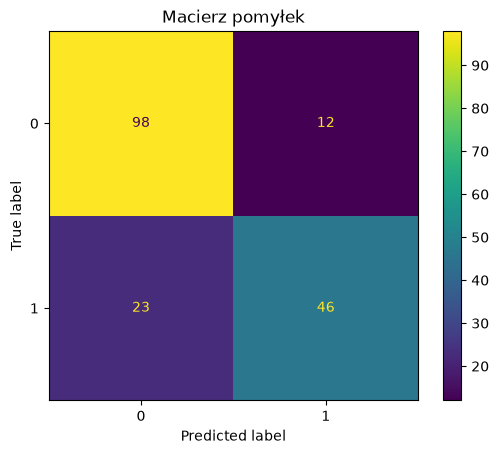

In [4]:
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test)
plt.title("Macierz pomyłek")
plt.show()

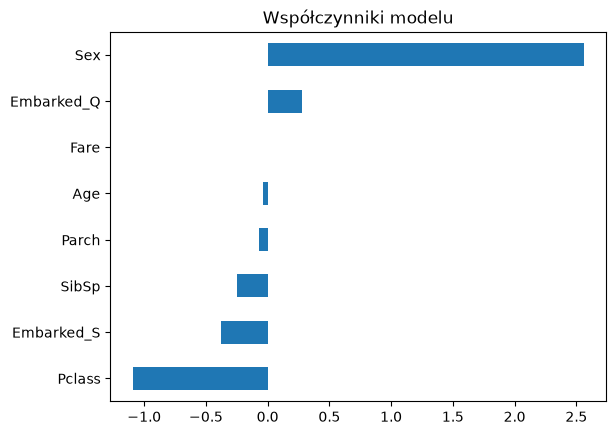

In [5]:
pd.Series(model.coef_[0], index=X_train.columns).sort_values().plot(kind="barh")
plt.title("Współczynniki modelu")
plt.show()